<a href="https://colab.research.google.com/github/revak18/science_fair_2026/blob/main/science_fair_2026_final_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# @title 1. SETUP & CONFIGURATION
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive, userdata

# 1. MOUNT & DIRECTORIES
drive.mount("/content/drive")
BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
HOURLY_LOAD_DIR = os.path.join(BASE_DIR, "hourly_load_raw")
WATER_IMPACT_DIR = os.path.join(BASE_DIR, "water_impact_raw")
RESULTS_FILE = "final_scientific_results_optimized.csv"

for d in [BASE_DIR, HOURLY_LOAD_DIR, WATER_IMPACT_DIR]:
    os.makedirs(d, exist_ok=True)

# 2. GLOBAL STUDY PARAMETERS
#REGIONS = ["PJME","COMED"]              # Region for study
REGIONS = ["PJME", "COMED", "AEP", "DAYTON", "DOM"]
AI_LOAD_LEVELS = [0.10, 0.20, 0.30]     # High load level to ensure visible impact
N_TRIALS = 30                           # High trials for statistical robustness
HORIZON_HOURS = 48                      # 48h window for job flexibility
PLANT_SIZE_MW = 500.0                   # Benchmark for "Plants Saved" metric
DROUGHT_FACTOR = 1.0                    # 1.0 = Normal, 1.2+ = Drought
RHO = 0.15

# 3. PARETO & SOLVER SETTINGS
# Use Log-scale weights to ensure the solver reacts to water
PARETO_WEIGHTS = [0.0, 1e-5, 1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

# "Stressor" Constants to force the Gas vs. Water trade-off
# 0.8 to 0.9	Robust Grid: The grid is strong and has plenty of spare capacity.
# 0.5 Stressed Grid: This simulates a "Peak Day" scenario where existing clean energy is pushed to its limit.
# 0.2 to 0.3	Emergency/Crisis: The grid has very little baseload capacity available.
STRESS_ALPHA = 0.6               # 60% base capacity forces Gas use


IMPORT_LIMIT_MW = 5000.0         # Grid interconnections
SLACK_REGIME = "tight"           # "tight": (1-4h) | "medium": (6-12h) | "loose": (12-24h) window for job movement

# 4. KAGGLE CREDENTIALS
try:
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print("Kaggle credentials loaded securely.")
except Exception:
    print("Warning: Kaggle credentials not found in Secrets.")

print(f"Setup Complete. Results will save to: {RESULTS_FILE}")

Mounted at /content/drive
Kaggle credentials loaded securely.
Setup Complete. Results will save to: final_scientific_results_optimized.csv


In [ ]:
# @title 2. DATA DOWNLOADERS (Run Once)
# ==========================================
# 2. DATA DOWNLOADERS (Run Once)
# ==========================================
import shutil
import zipfile

def download_data_if_missing():
#     # A. Grid Load (Kaggle)
#     if not os.listdir(HOURLY_LOAD_DIR):
#         print("Downloading Grid Load Data from Kaggle...")
#         # Secure system call using the directory from configuration
#         os.system(f'kaggle datasets download -d robikscube/hourly-energy-consumption -p "{BASE_DIR}"')
#         zip_path = os.path.join(BASE_DIR, "hourly-energy-consumption.zip")

#         if os.path.exists(zip_path):
#             with zipfile.ZipFile(zip_path, 'r') as z:
#                 z.extractall(HOURLY_LOAD_DIR)
#             print("Grid Data Extracted to hourly_load_raw.")
#         else:
#             print("Error: Zip file from Kaggle not found. Check credentials.")

    # B. Water Data (HydroShare / Manual)
    # We move the CSV into the specific sub-folder defined in Cell 1
    water_csv_name = "Water_IMPACT-Data_Consumption_2020.csv"
    water_csv_path = os.path.join(WATER_IMPACT_DIR, water_csv_name)

    if not os.path.exists(water_csv_path):
        # Check if it was accidentally downloaded to the BASE_DIR instead of WATER_IMPACT_DIR
        misplaced_path = os.path.join(BASE_DIR, water_csv_name)
        if os.path.exists(misplaced_path):
            print("Moving Water CSV to correct sub-directory...")
            shutil.move(misplaced_path, water_csv_path)
        else:
            print(f"CRITICAL: {water_csv_name} not found in {WATER_IMPACT_DIR}.")
            print("Please upload this file to your Drive folder manually to continue.")
    else:
        print("Water IMPACT Data verified in directory.")

download_data_if_missing()

Water IMPACT Data verified in directory.


In [16]:
# @title 3. DATA LOADERS
import pandas as pd
import numpy as np
import os
from datetime import timedelta

def load_ba_load(region: str):
    """Loads Grid Load with explicit cleaning and reindexing."""
    print(f"   -> Loading Grid Load for {region}...")
    fname = f"{region}_hourly.csv"
    path = os.path.join(HOURLY_LOAD_DIR, fname)

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    # Parse and rename
    df = pd.read_csv(path, parse_dates=["Datetime"])
    mw_col = [c for c in df.columns if c.endswith("_MW")]
    if not mw_col:
        raise ValueError(f"No *_MW column found in {path}")
    df = df.rename(columns={mw_col[0]: "load_MW"})

    # Clean indices and deduplicate
    df = df.set_index("Datetime").sort_index()
    df["load_MW"] = pd.to_numeric(df["load_MW"], errors="coerce")
    df = df.groupby(df.index).mean(numeric_only=True)

    # Reindex to full hourly timeline (fixed 'h' frequency)
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
    df = df.reindex(full_idx)

    # Clean outliers and fill gaps
    df.loc[df["load_MW"] < 0, "load_MW"] = np.nan
    lo, hi = df["load_MW"].quantile(0.001), df["load_MW"].quantile(0.999)
    df["load_MW"] = df["load_MW"].clip(lo, hi).interpolate(limit=3).ffill().bfill()

    return df


def load_water_intensity(region: str):
    """Loads Water Data mapped to BA regions."""
    print(f"   -> Loading Water Intensity for {region}...")

    REGION_MAP = {
        "PJME": "PJM", "PJMW": "PJM", "COMED": "PJM", "DAYTON": "PJM",
        "AEP": "PJM", "DOM": "PJM", "DUQ": "PJM", "FE": "PJM",
        "DEOK": "PJM", "NI": "PJM", "PJM": "PJM",
        "CISO": "CISO", "ERCOT": "ERCO", "SPP": "SWPP"
    }
    search_region = REGION_MAP.get(region, region)

    # Path check aligned with refined Setup
    path = os.path.join(WATER_IMPACT_DIR, "Water_IMPACT-Data_Consumption_2020.csv")
    if not os.path.exists(path):
        raise FileNotFoundError(f"Water file not found at {path}")

    df = pd.read_csv(path, parse_dates=["date"])

    # Filter and process BA-specific water intensity
    ba_col = "balancing_authority" if "balancing_authority" in df.columns else "ba_code"
    df = df[df[ba_col] == search_region].copy()
    if df.empty:
        raise ValueError(f"Region '{search_region}' not found in Water Data.")

    df = df.set_index("date").sort_index()
    df = df.groupby(df.index).mean(numeric_only=True)

    # Units: l/kWh to m3/MWh (1:1 conversion)
    target = "wci_primary" if "wci_primary" in df.columns else "w_consume_l_per_kwh"
    df["w_m3_per_MWh"] = pd.to_numeric(df[target], errors="coerce") * float(DROUGHT_FACTOR)

    # Final cleaning and resampling (fixed 'h' frequency)
    hi = float(df["w_m3_per_MWh"].quantile(0.999))
    df_clean = df[["w_m3_per_MWh"]].clip(0, hi).resample("h").mean()
    df_clean["w_m3_per_MWh"] = df_clean["w_m3_per_MWh"].interpolate(limit=3).ffill().bfill()

    return df_clean


def build_stressed_window(load_df, water_df, horizon_hours, top_k_candidates=50):
    """Extracts a high-load peak window for regional study."""
    print(f"   -> Extracting Peak {horizon_hours}h Window...")

    # Helper to ensure windows don't overlap too much
    def _dedupe_candidates(times, sep_hrs):
        kept = []
        for t in times:
            if all(abs((t - k).total_seconds()) >= sep_hrs * 3600 for k in kept):
                kept.append(t)
        return kept

    # 7-day rolling mean to identify seasonal peak
    rolling = load_df["load_MW"].rolling(window=24*7, min_periods=24).mean()
    if rolling.dropna().empty:
        raise ValueError("Load data insufficient for window extraction.")

    candidate_times = list(rolling.nlargest(top_k_candidates).index)
    candidate_times = _dedupe_candidates(candidate_times, 24)

    target_year = int(water_df.index.year[0]) # Align with 2020 water data

    for rank, peak_time in enumerate(candidate_times, start=1):
        # Center the window around the peak time
        start = peak_time - timedelta(hours=horizon_hours // 2)
        end = start + timedelta(hours=horizon_hours - 1)

        load_slice = load_df.loc[start:end].copy()
        if len(load_slice) < horizon_hours:
            continue

        # Year-shifting to match 2020 Water Impact dataset
        try:
            load_slice.index = [d.replace(year=target_year) for d in load_slice.index]
        except ValueError: # Handle leap day issues
            load_slice.index = [d.replace(year=target_year, month=3, day=1) if (d.month==2 and d.day==29) else d.replace(year=target_year) for d in load_slice.index]

        # Merge Load and Water
        window_df = pd.DataFrame(index=load_slice.index)
        window_df["L_base_MW"] = load_slice["load_MW"].values
        window_df["water_m3_per_mwh"] = water_df["w_m3_per_MWh"].reindex(window_df.index).interpolate(limit=3).ffill().bfill().values

        if not window_df.isna().any().any():
            print(f"      Selected window starting {start} (Rank #{rank})")
            return window_df

    raise ValueError(f"Could not find a valid {horizon_hours}h window for this region.")

In [17]:
# @title 4. FINAL CALIBRATED & OPTIMIZED SOLVER
import pulp
import numpy as np

def build_online_ai_load(window_df, L_max, fraction, rng):
    """
    Online (non-deferrable) AI load with diurnal pattern + noise.
    Works even if window_df.index is integers (CSV-loaded).
    """
    T = len(window_df)

    # Use hour_idx if present; else synthesize 0..T-1
    if isinstance(window_df, pd.DataFrame) and ("hour_idx" in window_df.columns):
        hour_of_day = (pd.to_numeric(window_df["hour_idx"], errors="coerce").fillna(0).astype(int).to_numpy()) % 24
    else:
        hour_of_day = (np.arange(T) % 24)

    base = fraction * L_max
    L_online = np.zeros(T, dtype=float)

    for t in range(T):
        mult = 1.3 if 9 <= hour_of_day[t] <= 21 else 0.4
        noise = rng.uniform(0.9, 1.1)
        L_online[t] = base * mult * noise

    return L_online


def _sample_slack_hours(rng, regime="mixed"):
    """Job slack (deadline flexibility) distribution in hours."""
    if regime == "tight":
        return int(rng.integers(1, 5))        # 1–4h
    if regime == "medium":
        return int(rng.integers(6, 13))       # 6–12h
    if regime == "loose":
        return int(rng.integers(12, 25))      # 12–24h

    # mixed: mostly medium, some tight/loose
    u = rng.random()
    if u < 0.2:
        return int(rng.integers(1, 5))
    if u < 0.85:
        return int(rng.integers(6, 13))
    return int(rng.integers(12, 25))

def generate_jobs_stochastic(T, t_peak, L_max, rng, ai_frac=0.10, slack_regime="tight", n_jobs=100):
    """
    Generates AI training jobs with high-precision energy scaling and strict power caps.
    """
    # 1. Configuration and Energy Targets
    target_ai_mw = L_max * ai_frac
    target_energy_mwh = target_ai_mw * T

    # 2. Sample Durations first [cite: 676, 677]
    durations = rng.integers(2, 7, size=n_jobs)

    # 3. Define Slack Ranges [cite: 666, 671]
    slack_map = {"tight": (1, 4), "medium": (6, 12), "loose": (12, 24)}
    s_min, s_max = slack_map.get(slack_regime, (1, 4))

    # 4. Build Initial Jobs with Boundary Safety [cite: 1530, 1531]
    arrivals = rng.normal(t_peak, 8, n_jobs)
    jobs = []

    # Real-world cap: no single job exceeds 5% of total deferrable AI capacity
    # job_power_cap = 0.05 * target_ai_mw

    total_dur = float(np.sum(durations))
    base_power = target_energy_mwh / total_dur

    min_cap_frac_needed = T / total_dur
    cap_frac = 0.05  # your preferred cap
    cap_frac_eff = max(cap_frac, 1.05 * min_cap_frac_needed)  # 5% buffer
    job_power_cap = cap_frac_eff * target_ai_mw




    for i in range(n_jobs):
        d_val = int(durations[i])
        # Initial guess distribution
        #p_val = (target_energy_mwh / np.sum(durations)) * rng.uniform(0.9, 1.1)

        p_val = base_power * rng.uniform(0.9, 1.1)

        p_val = min(p_val, job_power_cap)

        latest_start = max(0, T - d_val)
        release = int(np.clip(arrivals[i], 0, latest_start))

        slack = rng.integers(s_min, s_max + 1)
        deadline = max(min(T, release + d_val + slack), release + d_val)

        jobs.append({"id": i, "p": p_val, "d": d_val, "r": release, "e": deadline})

    # 5. HIGH-PRECISION ITERATIVE RENORMALIZATION
    # Fix: Scale only uncapped jobs to close the energy gap
    eps = 1e-9
    for _ in range(20):
        total_energy = sum(j["p"] * j["d"] for j in jobs)
        if total_energy <= 0:
            break

        gap = target_energy_mwh - total_energy
        if abs(gap) <= 1e-6 * target_energy_mwh:
            break  # Targeted energy reached

        # Identify 'free' jobs not yet at the power cap
        free = [j for j in jobs if j["p"] < job_power_cap - eps]
        if not free:
            break # All jobs capped; cannot add more energy

        free_energy = sum(j["p"] * j["d"] for j in free)
        if free_energy <= 0:
            break

        # Scale only the free jobs to close the remaining gap
        #scale = (free_energy + gap) / free_energy
        scale = max(0.0, (free_energy + gap) / free_energy)

        hit_cap = False
        for j in free:
            j["p"] *= scale
            if j["p"] > job_power_cap:
                j["p"] = job_power_cap
                hit_cap = True

        if not hit_cap and abs(target_energy_mwh - sum(j["p"] * j["d"] for j in jobs)) <= 1e-6 * target_energy_mwh:
            break

    # Final Verification
    final_energy = sum(j["p"] * j["d"] for j in jobs)
    if final_energy < 0.99 * target_energy_mwh:
        print(f"Warning: Energy target not met ({final_energy/target_energy_mwh:.1%}). "
              "Check if n_jobs or job_power_cap is too low.")

    return jobs

def solve_milp_with_schedule(
    L_base, L_online, jobs, w_vec,
    alpha=0.6, rho=0.15,
    water_weight=0.0,              # used in scalar mode
    import_limit_MW=0.0,
    mode="scalar",                 # "scalar", "gas_min", "water_min", "epsilon"
    water_epsilon=None,            # required when mode="epsilon"
    tie_break=1e-6                 # tiny coeff to avoid degeneracy
):
    """
    MILP Solver supporting:
      - scalar:    minimize C_gas + water_weight * W_peak
      - gas_min:   minimize C_gas (tie-break on W_peak)
      - water_min: minimize W_peak (tie-break on C_gas)  -> gives W_min reference
      - epsilon:   minimize C_gas s.t. W_peak <= water_epsilon

    Returns: status, deferr_mw (hourly), C_peak (gas), C_total (non+gas), W_peak (true series max)
    """
    L_base = np.asarray(L_base, dtype=float)
    L_online = np.asarray(L_online, dtype=float)
    w_vec = np.asarray(w_vec, dtype=float)

    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex", pulp.LpMinimize)

    # Variables
    C_gas = pulp.LpVariable("C_gas", lowBound=0)
    W_peak = pulp.LpVariable("W_peak", lowBound=0)

    # Binary schedule variables (only valid windows)
    x = pulp.LpVariable.dicts(
        "x",
        ((j['id'], t) for j in jobs for t in range(int(j['r']), int(j['e']))),
        cat=pulp.LpBinary
    )

    # Fixed non-gas capacity
    C_non = alpha * float(np.max(L_base))

    # Precompute active jobs by hour
    active_by_t = [[] for _ in range(T)]
    for j in jobs:
        r, e = int(j["r"]), int(j["e"])
        r = max(0, min(T, r))
        e = max(0, min(T, e))
        for t in range(r, e):
            active_by_t[t].append(j)

    # Objective modes
    if mode == "scalar":
        prob += C_gas + (float(water_weight) * W_peak)
    elif mode == "gas_min":
        prob += C_gas + (tie_break * W_peak)
    elif mode == "water_min":
        # avoid degenerate huge C_gas by tie-breaking on C_gas
        prob += W_peak + (tie_break * C_gas)
    elif mode == "epsilon":
        if water_epsilon is None or not np.isfinite(float(water_epsilon)):
            raise ValueError("mode='epsilon' requires a finite water_epsilon")
        prob += C_gas + (tie_break * W_peak)
        prob += W_peak <= float(water_epsilon)
    else:
        raise ValueError(f"Unknown mode: {mode}")

    # Hourly constraints
    for t in range(T):
        ai_def = pulp.lpSum(float(j["p"]) * x[(j["id"], t)] for j in active_by_t[t])
        L_tot = float(L_base[t]) + float(L_online[t]) + ai_def

        # adequacy
        prob += L_tot * (1 + float(rho)) <= C_non + C_gas + float(import_limit_MW)
        # water peak definition
        prob += L_tot * float(w_vec[t]) <= W_peak

    # Job duration constraints
    for j in jobs:
        jid = j["id"]
        r, e, d = int(j["r"]), int(j["e"]), int(j["d"])
        r = max(0, min(T, r))
        e = max(0, min(T, e))
        if e <= r:
            prob += 0 == d  # will make infeasible if bad job; safer than crashing
        else:
            prob += pulp.lpSum(x[(jid, t)] for t in range(r, e)) == d

    # Solve
    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=30, gapRel=0.01)
    prob.solve(solver)

    status = pulp.LpStatus[prob.status]
    deferr = np.zeros(T, dtype=float)

    if status in ("Optimal", "Not Solved"):
        for j in jobs:
            jid = j["id"]
            p = float(j["p"])
            r, e = int(j["r"]), int(j["e"])
            r = max(0, min(T, r))
            e = max(0, min(T, e))
            for t in range(r, e):
                v = pulp.value(x[(jid, t)])
                if v is not None and v > 0.5:
                    deferr[t] += p

    # True series peaks
    L_tot_series = L_base + L_online + deferr
    W_peak_true = float(np.max(L_tot_series * w_vec))

    c_gas_val = pulp.value(C_gas)
    c_gas_val = float(c_gas_val) if c_gas_val is not None else np.nan
    C_total = C_non + c_gas_val

    return {
        "status": status,
        "deferr_mw": deferr,
        "C_peak": c_gas_val,
        "C_total": float(C_total) if np.isfinite(C_total) else np.nan,
        "W_peak": W_peak_true
    }


In [18]:
# @title 5. Baseline Scheduling Policies + Capacity/Water Impact Calculator
import numpy as np

def schedule_no_flex(jobs, T):
    """
    Baseline A: No flexibility. Each job runs immediately at release time r
    for d hours (contiguously).
    """
    deferr = np.zeros(T, dtype=float)
    for j in jobs:
        r = int(j["r"])
        d = int(j["d"])
        p = float(j["p"])
        for t in range(r, min(T, r + d)):
            deferr[t] += p
    return deferr


def schedule_random_within_slack(jobs, T, rng):
    """
    Baseline B: Random scheduling within allowed window [r, e),
    selecting d distinct hours (non-contiguous allowed).
    """
    deferr = np.zeros(T, dtype=float)
    for j in jobs:
        r = max(0, int(j["r"]))
        e = min(T, int(j["e"]))
        d = int(j["d"])
        p = float(j["p"])

        feasible = list(range(r, e))
        if len(feasible) < d:
            # Not enough feasible hours: skip or force no-flex fallback
            # Here we fallback to no-flex behavior:
            for t in range(r, min(T, r + d)):
                deferr[t] += p
            continue

        chosen = rng.choice(feasible, size=d, replace=False)
        deferr[chosen] += p

    return deferr


def eval_impacts(L_base, L_online, deferr, w_vec, alpha, rho, import_limit):
    """
    Computes:
    - C_gas (MW): peak incremental gas capacity needed
    - C_total (MW): total capacity = C_non + C_gas
    - W_peak (m^3/h): worst-hour water index = max(L_total * w_vec)
    """
    L_base = np.asarray(L_base, dtype=float)
    L_online = np.asarray(L_online, dtype=float)
    deferr = np.asarray(deferr, dtype=float)
    w_vec = np.asarray(w_vec, dtype=float)

    L_tot = L_base + L_online + deferr

    C_non = alpha * float(np.max(L_base))

    # Required gas each hour (>=0), take max over time
    gas_needed = np.maximum(L_tot * (1 + rho) - C_non - float(import_limit), 0.0)
    C_gas = float(np.max(gas_needed))

    W_peak = float(np.max(L_tot * w_vec))
    C_total = float(C_non + C_gas)

    return C_gas, C_total, W_peak


def schedule_random_contiguous(jobs, T, rng):
    """
    Baseline B (realistic): Random contiguous scheduling within slack.
    Each job picks a random start time s such that the full duration fits in [r, e),
    then runs contiguously for d hours: s, s+1, ..., s+d-1.
    """
    deferr = np.zeros(T, dtype=float)

    for j in jobs:
        r = max(0, int(j["r"]))
        e = min(T, int(j["e"]))   # e is exclusive
        d = int(j["d"])
        p = float(j["p"])

        latest_start = e - d
        if latest_start < r:
            # Not enough room to fit contiguously: fallback to no-flex contiguous at release
            start = r
        else:
            start = int(rng.integers(r, latest_start + 1))

        end = min(T, start + d)
        deferr[start:end] += p

    return deferr

In [ ]:
# @title 6. PRE-CALCULATION EXECUTION (RUN ONCE, SAFE + TYPE GUARDS)
import pandas as pd
import numpy as np
import os

WINDOWS_PATH = os.path.join(BASE_DIR, "cleaned_regional_windows.csv")
WORKLOADS_PATH = os.path.join(BASE_DIR, "precalculated_workloads.csv")

def _as_int(x, name="value"):
    """Convert common numeric types to int; raise a clear error otherwise."""
    if isinstance(x, (int, np.integer)):
        return int(x)
    if isinstance(x, float) and np.isfinite(x):
        return int(x)
    raise TypeError(f"{name} must be a number (int/float). Got {type(x)}: {repr(x)[:120]}")

def run_window_precalc(force: bool = False):
    if (not force) and os.path.exists(WINDOWS_PATH):
        print("=== Phase 1: Windows already exist. Skipping (force=True to rebuild) ===")
        return

    print("=== Phase 1: Pre-calculating Regional Windows ===")
    window_results = []

    # Guard: HORIZON_HOURS must be an int
    horizon = _as_int(globals().get("HORIZON_HOURS", 48), "HORIZON_HOURS")
    print("HORIZON_HOURS =", horizon)

    for region in REGIONS:
        try:
            print(f"region: {region}")

            load_df = load_ba_load(region)
            water_df = load_water_intensity(region)

            # IMPORTANT: third arg must be int
            window = build_stressed_window(load_df, water_df, horizon)

            window = window.copy()
            window["region"] = str(region)
            window["hour_idx"] = np.arange(len(window), dtype=int)
            window_results.append(window)

            print(f"   [SUCCESS] Window ready for {region}")

        except Exception as e:
            print(f"   [ERROR] Could not process {region}: {e}")

    if window_results:
        final_windows_df = pd.concat(window_results, ignore_index=True)
        final_windows_df.to_csv(WINDOWS_PATH, index=False)
        print("Done. Windows saved.")
    else:
        print("[WARN] No windows generated. Check upstream load/water functions.")

def run_workload_precalc(force: bool = False):
    if (not force) and os.path.exists(WORKLOADS_PATH):
        print("=== Phase 2: Workloads already exist. Skipping (force=True to rebuild) ===")
        return

    print("\n=== Phase 2: Pre-calculating Stochastic Workloads ===")

    if not os.path.exists(WINDOWS_PATH):
        raise FileNotFoundError("Windows CSV missing. Run run_window_precalc() first.")

    windows_df = pd.read_csv(WINDOWS_PATH)
    all_trial_jobs = []

    # Build index lookup for stable seed logic
    region_to_i = {str(r): i for i, r in enumerate(REGIONS)}
    ai_levels = [float(a) for a in AI_LOAD_LEVELS]
    ai_to_i = {a: i for i, a in enumerate(ai_levels)}

    for region in REGIONS:
        rkey = str(region)
        region_window = windows_df[windows_df["region"].astype(str) == rkey].sort_values("hour_idx")
        if len(region_window) == 0:
            print(f"  [WARN] No window rows for region={region}. Skipping.")
            continue

        L_base = pd.to_numeric(region_window["L_base_MW"], errors="coerce").to_numpy()
        L_base = np.asarray(L_base, dtype=float)

        if len(L_base) == 0 or not np.isfinite(L_base).all():
            print(f"  [WARN] Bad L_base for region={region}. Skipping.")
            continue

        L_max = float(np.max(L_base))
        t_peak = int(np.argmax(L_base))
        T = int(len(L_base))  # <-- GUARANTEE INT

        for ai_frac in ai_levels:
            ai_def_portion = 0.5 * ai_frac  # deferrable portion
            print(f"Generating {N_TRIALS} trials for {region} | total AI={ai_frac:.0%} (deferrable={ai_def_portion:.0%})")

            for trial in range(_as_int(N_TRIALS, "N_TRIALS")):
                # Same seed logic as Cell 6
                seed = int(trial + 10_000*region_to_i[rkey] + 1_000_000*ai_to_i[ai_frac])
                rng = np.random.default_rng(seed)

                jobs = generate_jobs_stochastic(
                    T=T, t_peak=t_peak, L_max=L_max, rng=rng,
                    ai_frac=ai_def_portion, slack_regime=SLACK_REGIME
                )

                temp_df = pd.DataFrame(jobs)
                temp_df["region"] = rkey
                temp_df["ai_fraction"] = ai_frac   # store TOTAL AI level (Cell 6 expects this)
                temp_df["trial"] = int(trial)
                all_trial_jobs.append(temp_df)

    if all_trial_jobs:
        workload_df = pd.concat(all_trial_jobs, ignore_index=True)
        workload_df.to_csv(WORKLOADS_PATH, index=False)
        print("Done. Workloads saved.")
    else:
        print("[WARN] No workloads generated. Check generator settings.")

# Execute
run_window_precalc(force=True)
run_workload_precalc(force=True)

=== Phase 1: Pre-calculating Regional Windows ===
HORIZON_HOURS = 48
region: PJME
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak 48h Window...
      Selected window starting 2006-08-04 02:00:00 (Rank #1)
   [SUCCESS] Window ready for PJME
region: COMED
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...
   -> Extracting Peak 48h Window...
      Selected window starting 2011-07-23 09:00:00 (Rank #1)
   [SUCCESS] Window ready for COMED
region: AEP
   -> Loading Grid Load for AEP...
   -> Loading Water Intensity for AEP...
   -> Extracting Peak 48h Window...
      Selected window starting 2007-02-10 10:00:00 (Rank #1)
   [SUCCESS] Window ready for AEP
region: DAYTON
   -> Loading Grid Load for DAYTON...
   -> Loading Water Intensity for DAYTON...
   -> Extracting Peak 48h Window...
      Selected window starting 2006-08-03 14:00:00 (Rank #1)
   [SUCCESS] Window ready for DAYTON
region: DOM
   -> Loading Grid 

In [ ]:
# @title 7. EPSILON-CONSTRAINT MAIN LOOP
import os
import numpy as np
import pandas as pd

print("\n=== STARTING EPSILON-CONSTRAINT PARETO STUDY ===")

WINDOWS_PATH = os.path.join(BASE_DIR, "cleaned_regional_windows.csv")
WORKLOADS_PATH = os.path.join(BASE_DIR, "precalculated_workloads.csv")

windows_df = pd.read_csv(WINDOWS_PATH)
workloads_df = pd.read_csv(WORKLOADS_PATH)

# output file (don’t overwrite your scalarized results)
RESULTS_FILE_EPS = "final_results_epsilon_frontier.csv"
results = []

# Float-safe
workloads_df["ai_fraction"] = pd.to_numeric(workloads_df["ai_fraction"], errors="coerce")
workloads_df["trial"] = pd.to_numeric(workloads_df["trial"], errors="coerce")

# Build fast jobs lookup
jobs_map = {}
for (r, a, tr), grp in workloads_df.dropna(subset=["ai_fraction", "trial"]).groupby(["region", "ai_fraction", "trial"]):
    jobs_map[(str(r), float(a), int(tr))] = grp[["id","p","d","r","e"]].to_dict("records")

def get_jobs(region, ai_frac, trial, atol=1e-9):
    key = (str(region), float(ai_frac), int(trial))
    if key in jobs_map:
        return jobs_map[key]
    # fallback: find close float
    for (r, a, tr) in jobs_map.keys():
        if r == str(region) and tr == int(trial) and abs(a - float(ai_frac)) <= atol:
            return jobs_map[(r, a, tr)]
    return []

# Epsilon grid settings (per trial, auto-generated from Wmin..Wmax)
N_EPS = 6  # increase if you want smoother curves

region_to_i = {str(r): i for i, r in enumerate(REGIONS)}
ai_levels = [float(a) for a in AI_LOAD_LEVELS]
ai_to_i = {a: i for i, a in enumerate(ai_levels)}

for region_i, region in enumerate(REGIONS):
    rkey = str(region)
    print(f"\nProcessing Region: {rkey}")

    region_window = windows_df[windows_df["region"].astype(str) == rkey].sort_values("hour_idx")
    if len(region_window) == 0:
        print("  [WARN] No window rows; skipping.")
        continue

    L_base = pd.to_numeric(region_window["L_base_MW"], errors="coerce").to_numpy(dtype=float)
    w_vec  = pd.to_numeric(region_window["water_m3_per_mwh"], errors="coerce").to_numpy(dtype=float)

    if not np.isfinite(L_base).all() or not np.isfinite(w_vec).all() or len(L_base) != len(w_vec):
        raise ValueError(f"Bad L_base/w_vec for region={rkey}")

    L_max = float(np.max(L_base))
    T = len(L_base)

    for ai_i, ai_frac in enumerate(ai_levels):
        print(f" -> AI Level: {int(ai_frac*100)}%")

        ai_online_portion = 0.5 * ai_frac  # your calibration

        for trial in range(int(N_TRIALS)):
            print(f" --> TRIAL: {trial}")
            seed = int(trial + 10_000*region_to_i[rkey] + 1_000_000*ai_to_i[ai_frac])
            rng = np.random.default_rng(seed)

            jobs = get_jobs(rkey, ai_frac, trial)
            if len(jobs) == 0:
                print(f"   [WARN] Missing jobs for trial={trial}; skipping.")
                continue

            # Online load (uses your fixed build_online_ai_load)
            L_online = build_online_ai_load(region_window, L_max, ai_online_portion, rng)
            if len(L_online) != T or not np.isfinite(L_online).all():
                raise ValueError("Bad L_online generated")

            # === BASELINES (no MILP) ===
            def_no = schedule_no_flex(jobs, T)
            Cgas_no, Ctot_no, W_no = eval_impacts(
                L_base, L_online, def_no, w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit=IMPORT_LIMIT_MW
            )

            def_rand = schedule_random_contiguous(jobs, T, rng)
            Cgas_rand, Ctot_rand, W_rand = eval_impacts(
                L_base, L_online, def_rand, w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit=IMPORT_LIMIT_MW
            )


            # 1) Find W_min (water-first)
            sol_wmin = solve_milp_with_schedule(
                L_base=L_base, L_online=L_online, jobs=jobs, w_vec=w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW,
                mode="water_min"
            )
            if sol_wmin["status"] not in ("Optimal", "Not Solved") or not np.isfinite(sol_wmin["W_peak"]):
                print(f"   [WARN] water_min infeasible trial={trial}; skipping.")
                continue

            # 2) Find W_max (gas-first)
            sol_gmin = solve_milp_with_schedule(
                L_base=L_base, L_online=L_online, jobs=jobs, w_vec=w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW,
                mode="gas_min"
            )
            if sol_gmin["status"] not in ("Optimal", "Not Solved") or not np.isfinite(sol_gmin["W_peak"]):
                print(f"   [WARN] gas_min infeasible trial={trial}; skipping.")
                continue

            Wmin = float(sol_wmin["W_peak"])
            Wmax = float(sol_gmin["W_peak"])

            if Wmax < Wmin:
                Wmin, Wmax = Wmax, Wmin

            # build ε grid (small buffer to avoid numerical “just barely infeasible”)
            eps_list = np.linspace(Wmin, Wmax, N_EPS)
            eps_list[0] = Wmin * (1.0 + 1e-8)

            for eps_idx, eps in enumerate(eps_list):
                sol = solve_milp_with_schedule(
                    L_base=L_base,
                    L_online=L_online,
                    jobs=jobs,
                    w_vec=w_vec,
                    alpha=STRESS_ALPHA,
                    rho=RHO,
                    import_limit_MW=IMPORT_LIMIT_MW,
                    mode="epsilon",
                    water_epsilon=float(eps),
                )

                if sol["status"] in ("Optimal", "Not Solved"):
                    # Safe denominators (avoid divide-by-zero)
                    denom_gas_noflex = max(float(Cgas_no), 1e-9)
                    denom_w_noflex   = max(float(W_no), 1e-9)
                    denom_gas_rand   = max(float(Cgas_rand), 1e-9)
                    denom_w_rand     = max(float(W_rand), 1e-9)

                    results.append({
                        "region": rkey,
                        "ai_fraction": float(ai_frac),
                        "trial": int(trial),

                        # NEW: aligns frontier points across trials
                        "eps_idx": int(eps_idx),
                        "eps_frac": float(eps_idx / (len(eps_list) - 1)) if len(eps_list) > 1 else 0.0,
                        "Wmin": float(Wmin),
                        "Wmax": float(Wmax),

                        # Keep original epsilon value too (useful for plotting)
                        "epsilon_water_cap": float(eps),

                        # MILP outputs
                        "total_peak_mw": float(sol["C_total"]),
                        "gas_peak_mw": float(sol["C_peak"]),
                        "water_peak_m3h": float(sol["W_peak"]),

                        # Baselines (computed earlier in the trial)
                        "gas_no_flex_mw": float(Cgas_no),
                        "water_no_flex_m3h": float(W_no),
                        "gas_random_mw": float(Cgas_rand),
                        "water_random_m3h": float(W_rand),

                        # % improvements (positive = MILP better)
                        "gas_improve_pct_vs_noflex": 100.0 * (float(Cgas_no) - float(sol["C_peak"])) / denom_gas_noflex,
                        "water_improve_pct_vs_noflex": 100.0 * (float(W_no) - float(sol["W_peak"])) / denom_w_noflex,
                        "gas_improve_pct_vs_random": 100.0 * (float(Cgas_rand) - float(sol["C_peak"])) / denom_gas_rand,
                        "water_improve_pct_vs_random": 100.0 * (float(W_rand) - float(sol["W_peak"])) / denom_w_rand,
                    })

# Save
if results:
    out = pd.DataFrame(results)
    out_path = os.path.join(BASE_DIR, RESULTS_FILE_EPS)
    out.to_csv(out_path, index=False)
    print(f"\nSaved ε-frontier results to: {RESULTS_FILE_EPS}")
else:
    print("\n[WARN] No feasible ε-frontier points found.")


=== STARTING EPSILON-CONSTRAINT PARETO STUDY ===

Processing Region: PJME
 -> AI Level: 10%
 --> TRIAL: 0
 --> TRIAL: 1
 --> TRIAL: 2
 --> TRIAL: 3
 --> TRIAL: 4
 --> TRIAL: 5
 --> TRIAL: 6
 --> TRIAL: 7
 --> TRIAL: 8
 --> TRIAL: 9
 --> TRIAL: 10
 --> TRIAL: 11
 --> TRIAL: 12
 --> TRIAL: 13
 --> TRIAL: 14
 --> TRIAL: 15
 --> TRIAL: 16
 --> TRIAL: 17
 --> TRIAL: 18
 --> TRIAL: 19
 --> TRIAL: 20
 --> TRIAL: 21
 --> TRIAL: 22
 --> TRIAL: 23
 --> TRIAL: 24
 --> TRIAL: 25
 --> TRIAL: 26
 --> TRIAL: 27
 --> TRIAL: 28
 --> TRIAL: 29
 -> AI Level: 20%
 --> TRIAL: 0
 --> TRIAL: 1
 --> TRIAL: 2
 --> TRIAL: 3
 --> TRIAL: 4
 --> TRIAL: 5
 --> TRIAL: 6
 --> TRIAL: 7
 --> TRIAL: 8
 --> TRIAL: 9
 --> TRIAL: 10
 --> TRIAL: 11
 --> TRIAL: 12
 --> TRIAL: 13
 --> TRIAL: 14
 --> TRIAL: 15
 --> TRIAL: 16
 --> TRIAL: 17
 --> TRIAL: 18
 --> TRIAL: 19
 --> TRIAL: 20
 --> TRIAL: 21
 --> TRIAL: 22
 --> TRIAL: 23
 --> TRIAL: 24
 --> TRIAL: 25
 --> TRIAL: 26
 --> TRIAL: 27
 --> TRIAL: 28
 --> TRIAL: 29
 -> AI Le

In [2]:
RESULTS_FILE_EPS = "final_results_epsilon_frontier.csv"
out_path = os.path.join(BASE_DIR, RESULTS_FILE_EPS)
out = pd.read_csv(out_path)

In [4]:
# @title 8. Pareto Frontier Statistics (Mean ± Std, N=trials)
out.groupby(["region","ai_fraction","eps_idx"]).size().head(20)
summary = (out.groupby(["region","ai_fraction","eps_idx"])
  .agg(
    epsilon_cap_mean=("epsilon_water_cap","mean"),
    epsilon_cap_std =("epsilon_water_cap","std"),

    # MILP outcomes (absolute)
    gas_peak_mw_mean=("gas_peak_mw","mean"),
    gas_peak_mw_std =("gas_peak_mw","std"),
    water_peak_m3h_mean=("water_peak_m3h","mean"),
    water_peak_m3h_std =("water_peak_m3h","std"),

    # baselines (absolute)
    gas_no_flex_mw_mean=("gas_no_flex_mw","mean"),
    water_no_flex_m3h_mean=("water_no_flex_m3h","mean"),
    gas_random_mw_mean=("gas_random_mw","mean"),
    water_random_m3h_mean=("water_random_m3h","mean"),

    # improvements (%)
    gas_improve_vs_noflex_mean=("gas_improve_pct_vs_noflex","mean"),
    gas_improve_vs_noflex_std =("gas_improve_pct_vs_noflex","std"),
    water_improve_vs_noflex_mean=("water_improve_pct_vs_noflex","mean"),
    water_improve_vs_noflex_std =("water_improve_pct_vs_noflex","std"),
  )
  .reset_index()
)

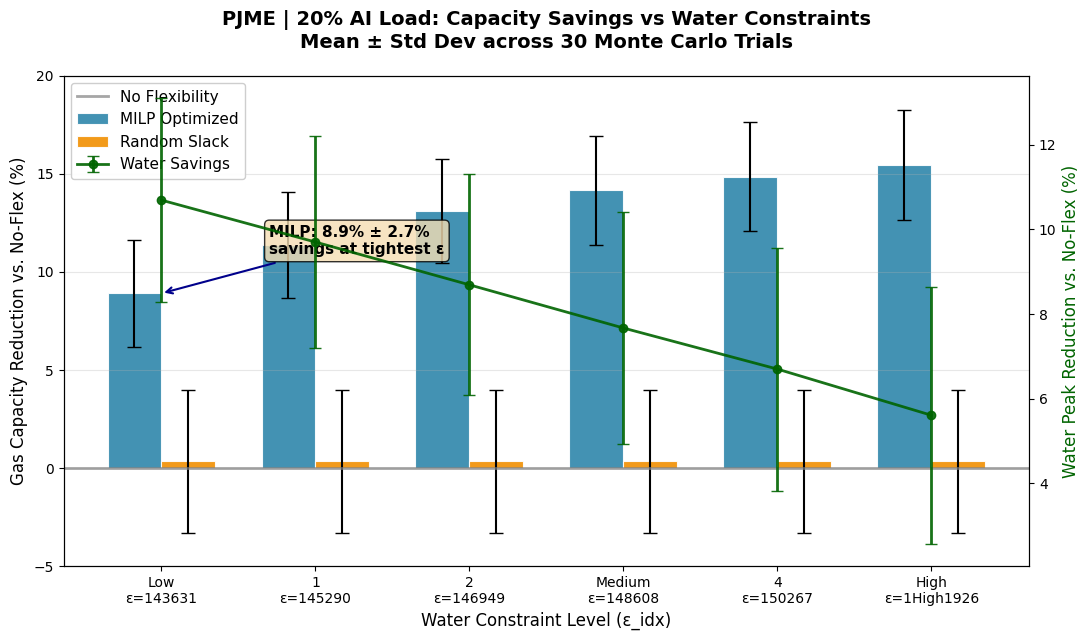

In [5]:
# @title 9. AI flexibility vs. baselines across water constraints

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Tuple

def plot_flexibility_benefits(df: pd.DataFrame, region: str = "COMED", ai_frac: float = 0.1) -> Tuple[plt.Figure, plt.Axes, pd.DataFrame]:
    """
    AI flexibility vs. baselines across water constraints.

    X: Water cap levels (ε_idx)
    Primary Y: Gas capacity reduction % vs. no-flex (MILP | Random | 0% line)
    Secondary Y: Water reduction % vs. no-flex (MILP only)

    Expected columns: region, ai_fraction, eps_idx, epsilon_water_cap,
    gas_improve_pct_vs_noflex, water_improve_pct_vs_noflex, gas_no_flex_mw, gas_random_mw
    """

    # === DATA PREPARATION ===
    work_df = df.copy()
    work_df["region"] = work_df["region"].astype(str).str.strip()

    # Robust numeric conversion
    for col in ["ai_fraction", "eps_idx", "epsilon_water_cap", "gas_improve_pct_vs_noflex",
                "water_improve_pct_vs_noflex", "gas_no_flex_mw", "gas_random_mw"]:
        work_df[col] = pd.to_numeric(work_df[col], errors='coerce')

    # Filter with tolerance for floating point
    filtered = work_df[
        (work_df["region"] == region) &
        np.isclose(work_df["ai_fraction"], ai_frac, atol=1e-8)
    ].dropna(subset=['eps_idx', 'gas_improve_pct_vs_noflex', 'gas_no_flex_mw', 'gas_random_mw'])

    if filtered.empty:
        raise ValueError(f"No valid data for {region}, {ai_frac*100:.0f}% AI")

    # MILP statistics by ε_idx (mean ± std across trials)
    milp_stats = (filtered.groupby('eps_idx')
                 .agg({
                     'epsilon_water_cap': ['mean', 'std'],
                     'gas_improve_pct_vs_noflex': ['mean', 'std'],
                     'water_improve_pct_vs_noflex': ['mean', 'std'],
                     'trial': 'nunique'
                 })
                 .round(2)
                 .reset_index())
    milp_stats.columns = ['eps_idx', 'eps_mean', 'eps_std', 'gas_mean', 'gas_std',
                         'water_mean', 'water_std', 'n_trials']

    # Random baseline (constant across ε_idx)
    trial_baselines = filtered.groupby('trial')[['gas_no_flex_mw', 'gas_random_mw']].first().dropna()
    random_pct = 100 * (trial_baselines['gas_no_flex_mw'] - trial_baselines['gas_random_mw']) / trial_baselines['gas_no_flex_mw']
    milp_stats['random_mean'] = random_pct.mean()
    milp_stats['random_std'] = random_pct.std()

    # === PLOTTING ===
    fig, ax = plt.subplots(figsize=(11, 6.5))
    x = np.arange(len(milp_stats))
    width = 0.35

    # Gas capacity bars (primary axis)
    colors = ['#2E86AB', '#F18F01']  # Professional blue/orange
    ax.bar(x - width/2, milp_stats['gas_mean'], width, yerr=milp_stats['gas_std'],
           capsize=5, label='MILP Optimized', color=colors[0], alpha=0.9, edgecolor='white', linewidth=0.8)
    ax.bar(x + width/2, milp_stats['random_mean'], width, yerr=milp_stats['random_std'],
           capsize=5, label='Random Slack', color=colors[1], alpha=0.9, edgecolor='white', linewidth=0.8)

    # No-flex reference (0%)
    ax.axhline(0, color='gray', lw=2, ls='-', alpha=0.7, label='No Flexibility')

    # Water reduction (secondary axis)
    ax2 = ax.twinx()
    ax2.errorbar(x, milp_stats['water_mean'], milp_stats['water_std'],
                fmt='o-', color='#006400', markersize=6, capsize=4, linewidth=2, label='Water Savings', alpha=0.9)

    # === FORMATTING ===
    ax.set_xlabel('Water Constraint Level (ε_idx)', fontsize=12, fontweight='medium')
    ax.set_ylabel('Gas Capacity Reduction vs. No-Flex (%)', fontsize=12, fontweight='medium', color='black')
    ax2.set_ylabel('Water Peak Reduction vs. No-Flex (%)', fontsize=12, fontweight='medium', color='#006400')

    # Clean x-axis labels: ε_idx + descriptive tags
    labels = [f'{int(row.eps_idx)}\nε={row.eps_mean:.0f}'
              for _, row in milp_stats.iterrows()]
    if len(labels) >= 3:
        labels[0] = labels[0].replace(f'{int(milp_stats.iloc[0].eps_idx)}', 'Low')
        labels[len(labels)//2] = labels[len(labels)//2].replace(f'{int(milp_stats.iloc[len(labels)//2].eps_idx)}', 'Medium')
        labels[-1] = labels[-1].replace(f'{int(milp_stats.iloc[-1].eps_idx)}', 'High')

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0, ha='center')

    # Professional title with stats
    n_trials = int(filtered['trial'].nunique())
    title = (f'{region.upper()} | {int(ai_frac*100)}% AI Load: Capacity Savings vs Water Constraints\n'
             f'Mean ± Std Dev across {n_trials} Monte Carlo Trials')
    ax.set_title(title, fontsize=14, fontweight='bold', pad=20)

    # Unified legend
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(handles1 + handles2, labels1 + labels2, frameon=True, fancybox=True,
              framealpha=0.95, loc='upper left', fontsize=11)

    # Grid and limits
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(-5, max(20, milp_stats['gas_mean'].max() * 1.1))

    # Key result callout
    best_gas = milp_stats.loc[0, 'gas_mean']  # Tightest water constraint
    ax.annotate(f'MILP: {best_gas:.1f}% ± {milp_stats.loc[0, "gas_std"]:.1f}%\nsavings at tightest ε',
                xy=(0, best_gas), xytext=(0.7, best_gas+2),
                arrowprops=dict(arrowstyle='->', color='darkblue', lw=1.5),
                fontsize=11, fontweight='bold', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    plt.tight_layout()
    return fig, ax, milp_stats

# Usage
fig, ax, stats = plot_flexibility_benefits(out, region="PJME", ai_frac=0.2)

<>:68: SyntaxWarning: invalid escape sequence '\p'
<>:68: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipython-input-3983907549.py:68: SyntaxWarning: invalid escape sequence '\p'
  ax1.text(0.01, -0.12, "*Error bars: $\pm$1 Std. Dev. (30 trials)",


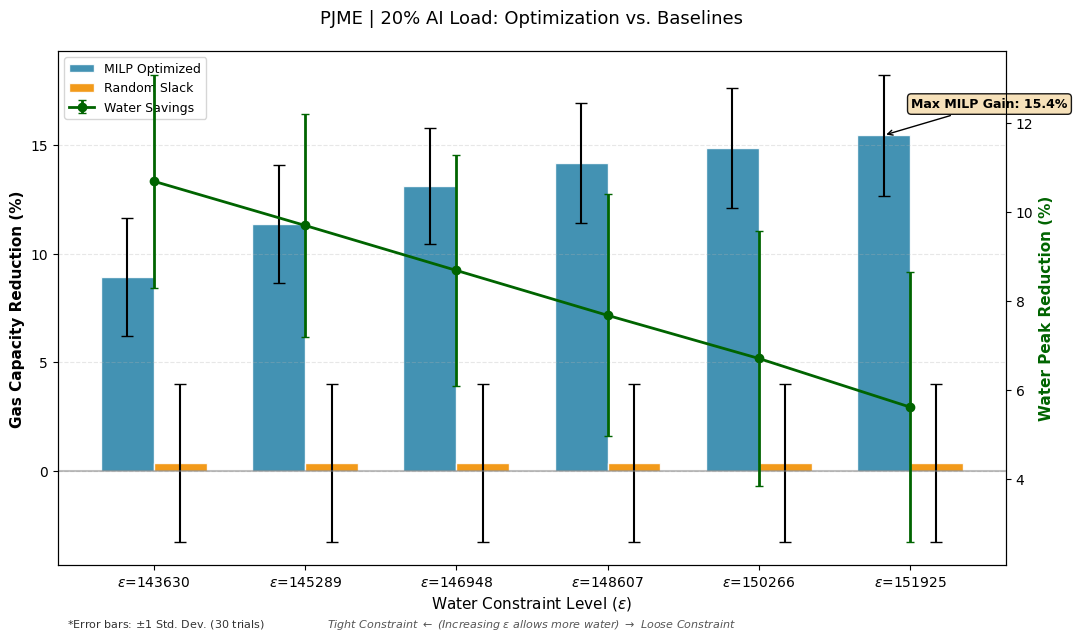

In [10]:
# @title 9A. AI flexibility vs. baselines across water constraints - alternate for 9
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Tuple

def plot_flexibility_benefits_final(df: pd.DataFrame, region: str = "PJME", ai_frac: float = 0.2) -> Tuple[plt.Figure, plt.Axes]:
    # === 1. DATA PREPARATION ===
    work_df = df.copy()
    work_df["region"] = work_df["region"].astype(str).str.strip()

    cols = ["ai_fraction", "eps_idx", "epsilon_water_cap", "gas_improve_pct_vs_noflex",
            "water_improve_pct_vs_noflex", "gas_no_flex_mw", "gas_random_mw"]
    for col in cols:
        work_df[col] = pd.to_numeric(work_df[col], errors='coerce')

    filtered = work_df[
        (work_df["region"] == region) &
        np.isclose(work_df["ai_fraction"], ai_frac, atol=1e-8)
    ].dropna(subset=['eps_idx', 'gas_improve_pct_vs_noflex'])

    # MILP Stats
    milp_stats = filtered.groupby('eps_idx').agg({
        'epsilon_water_cap': 'mean',
        'gas_improve_pct_vs_noflex': ['mean', 'std'],
        'water_improve_pct_vs_noflex': ['mean', 'std']
    }).reset_index()
    milp_stats.columns = ['eps_idx', 'eps_mean', 'gas_mean', 'gas_std', 'water_mean', 'water_std']

    # Random Baseline calculation
    trial_baselines = filtered.groupby('trial')[['gas_no_flex_mw', 'gas_random_mw']].first().dropna()
    random_pct = 100 * (trial_baselines['gas_no_flex_mw'] - trial_baselines['gas_random_mw']) / trial_baselines['gas_no_flex_mw']
    r_mean, r_std = random_pct.mean(), random_pct.std()

    # === 2. PLOTTING ===
    fig, ax1 = plt.subplots(figsize=(11, 6.5))
    x = np.arange(len(milp_stats))
    width = 0.35

    # Gas Capacity Bars (Primary Axis)
    ax1.bar(x - width/2, milp_stats['gas_mean'], width, yerr=milp_stats['gas_std'],
            label='MILP Optimized', color='#2E86AB', alpha=0.9, capsize=4, edgecolor='white')

    # Explicitly showing Random Slack
    ax1.bar(x + width/2, [r_mean]*len(x), width, yerr=[r_std]*len(x),
            label='Random Slack', color='#F18F01', alpha=0.9, capsize=4, edgecolor='white')

    # Water Reduction Line (Secondary Axis)
    ax2 = ax1.twinx()
    ax2.errorbar(x, milp_stats['water_mean'], yerr=milp_stats['water_std'],
                 fmt='o-', color='#006400', linewidth=2, markersize=6, capsize=3, label='Water Savings')

    # === 3. FORMATTING & COMMENTARY ===
    ax1.axhline(0, color='gray', lw=1.5, alpha=0.5)
    ax1.set_ylabel('Gas Capacity Reduction (%)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Water Peak Reduction (%)', fontsize=11, fontweight='bold', color='#006400')

    # Fix X-Axis labels using Raw Strings (r"") to avoid SyntaxWarnings
    labels = [rf"$\epsilon$={int(m)}" for m in milp_stats['eps_mean']]
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels)
    ax1.set_xlabel(r'Water Constraint Level ($\epsilon$)', fontsize=11)

    # X-axis commentary
    ax1.text(0.5, -0.12, r"Tight Constraint $\leftarrow$ (Increasing $\epsilon$ allows more water) $\rightarrow$ Loose Constraint",
             transform=ax1.transAxes, ha='center', fontsize=8, color='#555555', fontstyle='italic')

    # Error bar note
    ax1.text(0.01, -0.12, "*Error bars: $\pm$1 Std. Dev. (30 trials)",
             transform=ax1.transAxes, fontsize=8, alpha=0.8)

    # Fixed Yellow Label - positioned relative to the plot area to prevent "haywire" movement
    ax1.annotate(f'Max MILP Gain: {milp_stats["gas_mean"].max():.1f}%',
                 xy=(x[np.argmax(milp_stats['gas_mean'])] - width/2, milp_stats['gas_mean'].max()),
                 xytext=(20, 20), textcoords='offset points',
                 arrowprops=dict(arrowstyle='->', color='black', lw=1),
                 bbox=dict(boxstyle='round,pad=0.3', fc='wheat', alpha=0.9),
                 fontsize=9, fontweight='bold')

    ax1.set_title(f'{region} | {int(ai_frac*100)}% AI Load: Optimization vs. Baselines', fontsize=13, pad=20)
    ax1.grid(axis='y', linestyle='--', alpha=0.3)

    # Legend
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9, frameon=True)

    plt.tight_layout()
    return fig, ax1

# usage: fig, ax = plot_flexibility_benefits_final(out)
fig, ax = plot_flexibility_benefits_final(out)


CAPTION:
Pareto frontier of gas capacity vs. water peak for PJME 20% AI load. Each blue point is an ε-constrained MILP schedule (mean across trials); red X and orange square are no-flex and random-contiguous baselines. The curve shows the trade-off between reducing gas capacity and limiting peak water impact under grid stress.


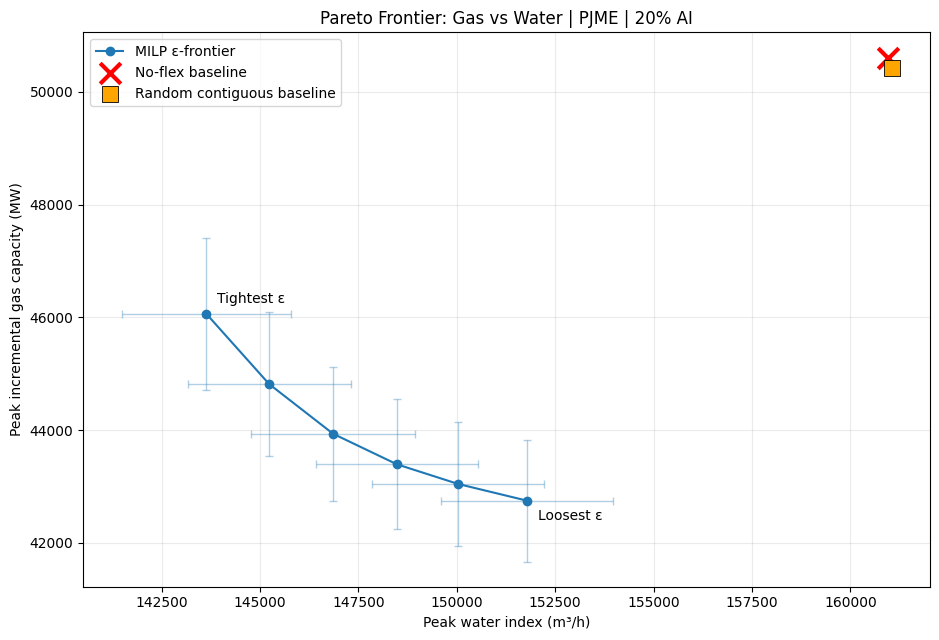

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_pareto_frontier_with_baselines(
    out: pd.DataFrame,
    region: str = "COMED",
    ai_frac: float = 0.10,
    sort_by: str = "eps_idx",          # "eps_idx" or "epsilon_water_cap"
    show_errorbars: bool = True,
):
    """
    Pareto Frontier With Baselines (ISEF-style)

    X-axis: water_peak_m3h_mean (m^3/h)  -> computed as mean water_peak_m3h across trials per eps point
    Y-axis: gas_peak_mw_mean (MW)        -> computed as mean gas_peak_mw across trials per eps point

    Baselines (computed across trials; pulled once per trial):
      - No-flex: red X
      - Random contiguous: orange square
      - MILP frontier: blue circles + line (ordered by eps_idx or epsilon cap)

    Requires `out` to contain at least:
      region, ai_fraction, trial, eps_idx, epsilon_water_cap,
      gas_peak_mw, water_peak_m3h,
      gas_no_flex_mw, water_no_flex_m3h,
      gas_random_mw, water_random_m3h
    """
    df = out.copy()

    # --- robust filtering ---
    df["region"] = df["region"].astype(str).str.strip()
    df["ai_fraction"] = pd.to_numeric(df["ai_fraction"], errors="coerce")
    df["trial"] = pd.to_numeric(df["trial"], errors="coerce")

    df = df[(df["region"] == str(region)) & (np.isclose(df["ai_fraction"], float(ai_frac), atol=1e-9))]
    if df.empty:
        raise ValueError(f"No rows found for region={region} and ai_frac={ai_frac}")

    # Ensure numeric
    num_cols = [
        "eps_idx","epsilon_water_cap","gas_peak_mw","water_peak_m3h",
        "gas_no_flex_mw","water_no_flex_m3h","gas_random_mw","water_random_m3h"
    ]
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(subset=["eps_idx","epsilon_water_cap","gas_peak_mw","water_peak_m3h","trial"])
    if df.empty:
        raise ValueError("After numeric cleanup, no valid MILP rows remain.")

    # --- frontier stats across trials for each eps point ---
    frontier = (
        df.groupby("eps_idx", as_index=False)
          .agg(
              epsilon_mean=("epsilon_water_cap","mean"),
              water_mean=("water_peak_m3h","mean"),
              water_std =("water_peak_m3h","std"),
              gas_mean  =("gas_peak_mw","mean"),
              gas_std   =("gas_peak_mw","std"),
              n_trials  =("trial","nunique"),
          )
    )

    if sort_by == "epsilon_water_cap":
        frontier = frontier.sort_values("epsilon_mean")
    else:
        frontier = frontier.sort_values("eps_idx")

    # --- baselines across trials (grab one row per trial; baseline columns constant within trial) ---
    per_trial = (
        df.sort_values("eps_idx")
          .groupby("trial", as_index=False)
          .first()
          .dropna(subset=["gas_no_flex_mw","water_no_flex_m3h","gas_random_mw","water_random_m3h"])
    )

    noflex_gas   = per_trial["gas_no_flex_mw"].mean()
    noflex_water = per_trial["water_no_flex_m3h"].mean()
    rand_gas     = per_trial["gas_random_mw"].mean()
    rand_water   = per_trial["water_random_m3h"].mean()

    # --- plot ---
    fig, ax = plt.subplots(figsize=(9.5, 6.5))

    # MILP frontier (blue circles + line)
    ax.plot(
        frontier["water_mean"], frontier["gas_mean"],
        "-o", color="tab:blue", markerfacecolor="tab:blue",
        label="MILP ε-frontier"
    )

    # Optional error bars (mean ± std across trials)
    if show_errorbars:
        ax.errorbar(
            frontier["water_mean"], frontier["gas_mean"],
            xerr=frontier["water_std"], yerr=frontier["gas_std"],
            fmt="none", ecolor="tab:blue", alpha=0.35, capsize=3, linewidth=1
        )

    # Baselines
    ax.scatter(
        [noflex_water], [noflex_gas],
        marker="x", s=220, linewidths=3, color="red",
        label="No-flex baseline"
    )
    ax.scatter(
        [rand_water], [rand_gas],
        marker="s", s=140, color="orange", edgecolor="black", linewidth=0.6,
        label="Random contiguous baseline"
    )

    # Labels/title
    ax.set_xlabel("Peak water index (m³/h)")
    ax.set_ylabel("Peak incremental gas capacity (MW)")
    ax.set_title(f"Pareto Frontier: Gas vs Water | {region.upper()} | {int(ai_frac*100)}% AI")

    ax.grid(True, alpha=0.25)
    ax.legend(loc="best", frameon=True)

    # Helpful annotations (tightest & loosest points)
    first = frontier.iloc[0]
    last  = frontier.iloc[-1]
    ax.annotate("Tightest ε", (first["water_mean"], first["gas_mean"]),
                textcoords="offset points", xytext=(8, 8), fontsize=10)
    ax.annotate("Loosest ε", (last["water_mean"], last["gas_mean"]),
                textcoords="offset points", xytext=(8, -14), fontsize=10)

    # Caption/story (optional: print it so you can paste into poster)
    caption = (
        f"Pareto frontier of gas capacity vs. water peak for {region.upper()} {int(ai_frac*100)}% AI load. "
        f"Each blue point is an ε-constrained MILP schedule (mean across trials); red X and orange square are "
        f"no-flex and random-contiguous baselines. The curve shows the trade-off between reducing gas capacity "
        f"and limiting peak water impact under grid stress."
    )
    print("\nCAPTION:\n" + caption)

    plt.tight_layout()
    return fig, ax, frontier


# --- usage ---
fig, ax, frontier = plot_pareto_frontier_with_baselines(out, region="PJME", ai_frac=0.20)
plt.show()



CAPTION:
48-hour load profile for COMED 10% AI. Red: if AI jobs run as soon as they are ready (no flexibility), the peak increases. Blue: ε-constrained MILP shifts deferrable work into shoulder hours, shaving the peak while keeping energy similar. Green shading marks highest water-intensity hours (top 20%).


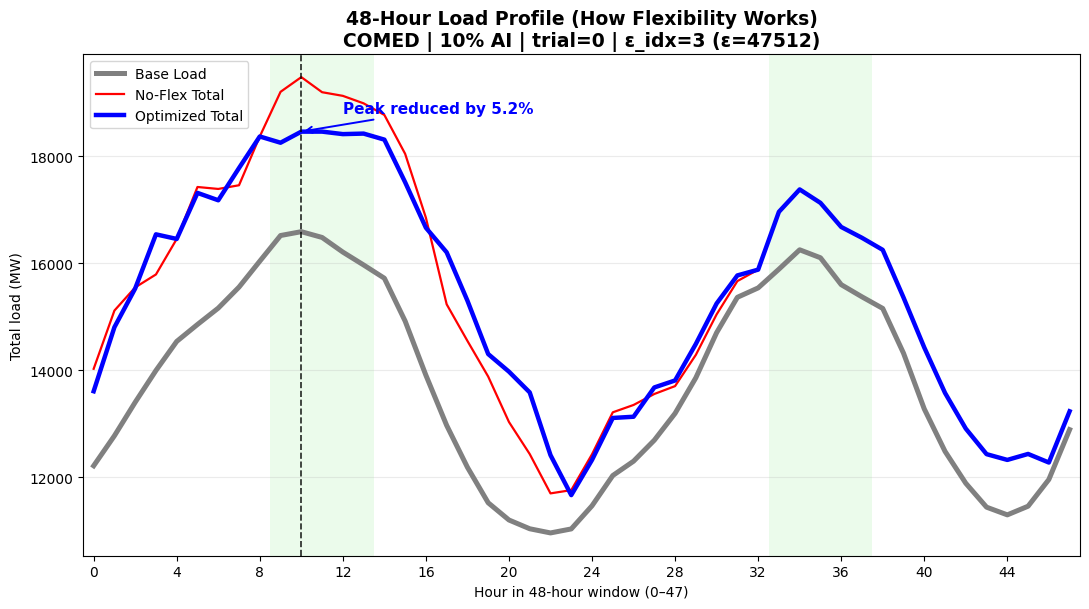

In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_48h_load_profile_from_saved_files(
    BASE_DIR: str,
    out: pd.DataFrame,
    *,
    region: str = "COMED",
    ai_frac: float = 0.10,        # total AI level stored in out["ai_fraction"]
    trial: int = 0,
    eps_pick: str = "mid",        # "tight" (low eps_idx), "mid", "loose" (high eps_idx)
    eps_idx: int | None = None,   # override eps_pick if provided
    water_top_frac: float = 0.20  # shade top 20% water-intensity hours
):
    WINDOWS_PATH = os.path.join(BASE_DIR, "cleaned_regional_windows.csv")
    WORKLOADS_PATH = os.path.join(BASE_DIR, "precalculated_workloads.csv")

    if not os.path.exists(WINDOWS_PATH) or not os.path.exists(WORKLOADS_PATH):
        raise FileNotFoundError(
            "Missing inputs for 48h profile. You need BOTH:\n"
            f"  - {WINDOWS_PATH}\n"
            f"  - {WORKLOADS_PATH}\n"
            "These are created by your Phase 1/2 precalc cells (run_window_precalc + run_workload_precalc)."
        )

    windows_df = pd.read_csv(WINDOWS_PATH)
    workloads_df = pd.read_csv(WORKLOADS_PATH)

    # --- window for region ---
    wdf = windows_df.copy()
    wdf["region"] = wdf["region"].astype(str).str.strip()
    wdf = wdf[wdf["region"] == str(region)].copy()
    if wdf.empty:
        raise ValueError(f"No window found for region={region} in {WINDOWS_PATH}")

    wdf["hour_idx"] = pd.to_numeric(wdf["hour_idx"], errors="coerce")
    wdf = wdf.sort_values("hour_idx")
    L_base = pd.to_numeric(wdf["L_base_MW"], errors="coerce").to_numpy(dtype=float)
    w_vec  = pd.to_numeric(wdf["water_m3_per_mwh"], errors="coerce").to_numpy(dtype=float)
    if not np.isfinite(L_base).all() or not np.isfinite(w_vec).all():
        raise ValueError("Non-finite values in L_base or w_vec (check cleaned_regional_windows.csv).")

    T = int(len(L_base))
    L_max = float(np.max(L_base))

    # --- jobs for scenario ---
    jdf = workloads_df.copy()
    jdf["region"] = jdf["region"].astype(str).str.strip()
    jdf["ai_fraction"] = pd.to_numeric(jdf["ai_fraction"], errors="coerce")
    jdf["trial"] = pd.to_numeric(jdf["trial"], errors="coerce")

    jobs_rows = jdf[
        (jdf["region"] == str(region)) &
        (np.isclose(jdf["ai_fraction"], float(ai_frac), atol=1e-9)) &
        (jdf["trial"].astype(int) == int(trial))
    ].copy()
    if jobs_rows.empty:
        raise ValueError(f"No jobs found for region={region}, ai_frac={ai_frac}, trial={trial} in {WORKLOADS_PATH}")

    jobs = jobs_rows[["id","p","d","r","e"]].to_dict("records")

    # --- reconstruct SAME seed logic used in your Cell 6 ---
    # Prefer your original REGIONS / AI_LOAD_LEVELS ordering if present (best match).
    unique_regions = list(jdf["region"].dropna().astype(str).unique())
    unique_ai = sorted(list(jdf["ai_fraction"].dropna().astype(float).unique()))

    try:
        region_to_i = {str(r): i for i, r in enumerate(REGIONS)}  # noqa: F821
    except Exception:
        region_to_i = {r: i for i, r in enumerate(unique_regions)}

    try:
        ai_levels = [float(a) for a in AI_LOAD_LEVELS]            # noqa: F821
        ai_to_i = {a: i for i, a in enumerate(ai_levels)}
    except Exception:
        ai_to_i = {a: i for i, a in enumerate(unique_ai)}

    # Handle float match for ai_frac
    if float(ai_frac) not in ai_to_i:
        closest = min(ai_to_i.keys(), key=lambda x: abs(x - float(ai_frac)))
        if abs(closest - float(ai_frac)) > 1e-6:
            raise ValueError(f"ai_frac={ai_frac} not found in AI levels; nearest is {closest}")
        ai_key = closest
    else:
        ai_key = float(ai_frac)

    if str(region) not in region_to_i:
        raise ValueError(f"region={region} not found in region index mapping.")

    seed = int(int(trial) + 10_000*region_to_i[str(region)] + 1_000_000*ai_to_i[ai_key])
    rng = np.random.default_rng(seed)

    # Online AI portion (your calibration)
    ai_online_portion = 0.5 * float(ai_frac)
    L_online = build_online_ai_load(wdf, L_max, ai_online_portion, rng)  # must exist
    L_online = np.asarray(L_online, dtype=float)
    if len(L_online) != T or not np.isfinite(L_online).all():
        raise ValueError("Bad L_online generated.")

    # --- pick ε point from out (for this region/ai/trial) ---
    odf = out.copy()
    odf["region"] = odf["region"].astype(str).str.strip()
    odf["ai_fraction"] = pd.to_numeric(odf["ai_fraction"], errors="coerce")
    odf["trial"] = pd.to_numeric(odf["trial"], errors="coerce")
    odf["eps_idx"] = pd.to_numeric(odf["eps_idx"], errors="coerce")
    odf["epsilon_water_cap"] = pd.to_numeric(odf["epsilon_water_cap"], errors="coerce")

    sub = odf[
        (odf["region"] == str(region)) &
        (np.isclose(odf["ai_fraction"], float(ai_frac), atol=1e-9)) &
        (odf["trial"].astype(int) == int(trial))
    ].dropna(subset=["eps_idx","epsilon_water_cap"]).copy()

    if sub.empty:
        raise ValueError("No ε results found in `out` for this region/ai/trial.")

    sub = sub.sort_values("eps_idx")
    if eps_idx is None:
        if eps_pick == "tight":
            eps_idx = int(sub["eps_idx"].iloc[0])
        elif eps_pick == "loose":
            eps_idx = int(sub["eps_idx"].iloc[-1])
        else:
            eps_idx = int(sub["eps_idx"].iloc[len(sub)//2])

    row = sub[sub["eps_idx"].astype(int) == int(eps_idx)]
    if row.empty:
        raise ValueError(f"eps_idx={eps_idx} not available for this trial. Have: {sorted(sub['eps_idx'].unique())}")

    water_epsilon = float(row["epsilon_water_cap"].iloc[0])

    # --- schedules ---
    def_no = schedule_no_flex(jobs, T)  # must exist
    L_no = L_base + L_online + def_no

    sol = solve_milp_with_schedule(
        L_base=L_base,
        L_online=L_online,
        jobs=jobs,
        w_vec=w_vec,
        alpha=STRESS_ALPHA,            # must exist
        rho=RHO,                       # must exist
        import_limit_MW=IMPORT_LIMIT_MW,# must exist
        mode="epsilon",
        water_epsilon=water_epsilon
    )
    if sol["status"] not in ("Optimal", "Not Solved"):
        raise RuntimeError(f"MILP status={sol['status']} (not usable).")

    def_opt = np.asarray(sol["deferr_mw"], dtype=float)
    L_opt = L_base + L_online + def_opt

    # --- cues ---
    peak_t = int(np.argmax(L_no))
    peak_no = float(np.max(L_no))
    peak_opt = float(np.max(L_opt))
    peak_reduction_pct = 100.0 * (peak_no - peak_opt) / max(peak_no, 1e-9)

    # water shading (top X%)
    thr = float(np.quantile(w_vec, 1.0 - float(water_top_frac)))
    high_water = (w_vec >= thr)

    # --- plot ---
    x = np.arange(T)
    fig, ax = plt.subplots(figsize=(11, 6.2))

    # Shade high-water hours
    for t in range(T):
        if high_water[t]:
            ax.axvspan(t - 0.5, t + 0.5, color="#c7f5c7", alpha=0.35, linewidth=0)

    ax.plot(x, L_base, color="gray", linewidth=3.6, label="Base Load")
    ax.plot(x, L_no,   color="red",  linewidth=1.6, label="No-Flex Total")
    ax.plot(x, L_opt,  color="blue", linewidth=3.2, label="Optimized Total")

    # peak marker based on no-flex
    ax.axvline(peak_t, color="black", linestyle="--", linewidth=1.2, alpha=0.85)

    ax.annotate(
        f"Peak reduced by {peak_reduction_pct:.1f}%",
        xy=(peak_t, peak_opt),
        xytext=(min(T-1, peak_t + 2), peak_opt + 0.04*(peak_no - np.min(L_base) + 1)),
        arrowprops=dict(arrowstyle="->", color="blue", lw=1.4),
        fontsize=11, fontweight="bold", color="blue"
    )

    ax.set_xlim(-0.5, T - 0.5)
    ax.set_xticks(np.arange(0, T, 4))
    ax.set_xlabel("Hour in 48-hour window (0–47)")
    ax.set_ylabel("Total load (MW)")
    ax.grid(True, axis="y", alpha=0.25)

    ax.set_title(
        f"48-Hour Load Profile (How Flexibility Works)\n"
        f"{region.upper()} | {int(ai_frac*100)}% AI | trial={trial} | ε_idx={eps_idx} (ε={water_epsilon:.0f})",
        fontsize=13.5, fontweight="bold"
    )

    ax.legend(loc="upper left", frameon=True)
    plt.tight_layout()

    caption = (
        f"48-hour load profile for {region.upper()} {int(ai_frac*100)}% AI. "
        f"Red: if AI jobs run as soon as they are ready (no flexibility), the peak increases. "
        f"Blue: ε-constrained MILP shifts deferrable work into shoulder hours, shaving the peak while keeping energy similar. "
        f"Green shading marks highest water-intensity hours (top {int(water_top_frac*100)}%)."
    )
    print("\nCAPTION:\n" + caption)

    return fig, ax


# --- Usage (you already have out loaded) ---
fig, ax = plot_48h_load_profile_from_saved_files(
    BASE_DIR=BASE_DIR,
    out=out,
    region="COMED",
    ai_frac=0.10,
    trial=0,
    eps_pick="mid",   # or "tight" / "loose"
    water_top_frac=0.20
)
plt.show()


/tmp/ipython-input-2633155784.py:77: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["region", "ai_fraction", "water_level", "trial"], as_index=False)
/tmp/ipython-input-2633155784.py:83: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per_trial.groupby(["region", "ai_fraction", "water_level"], as_index=False)


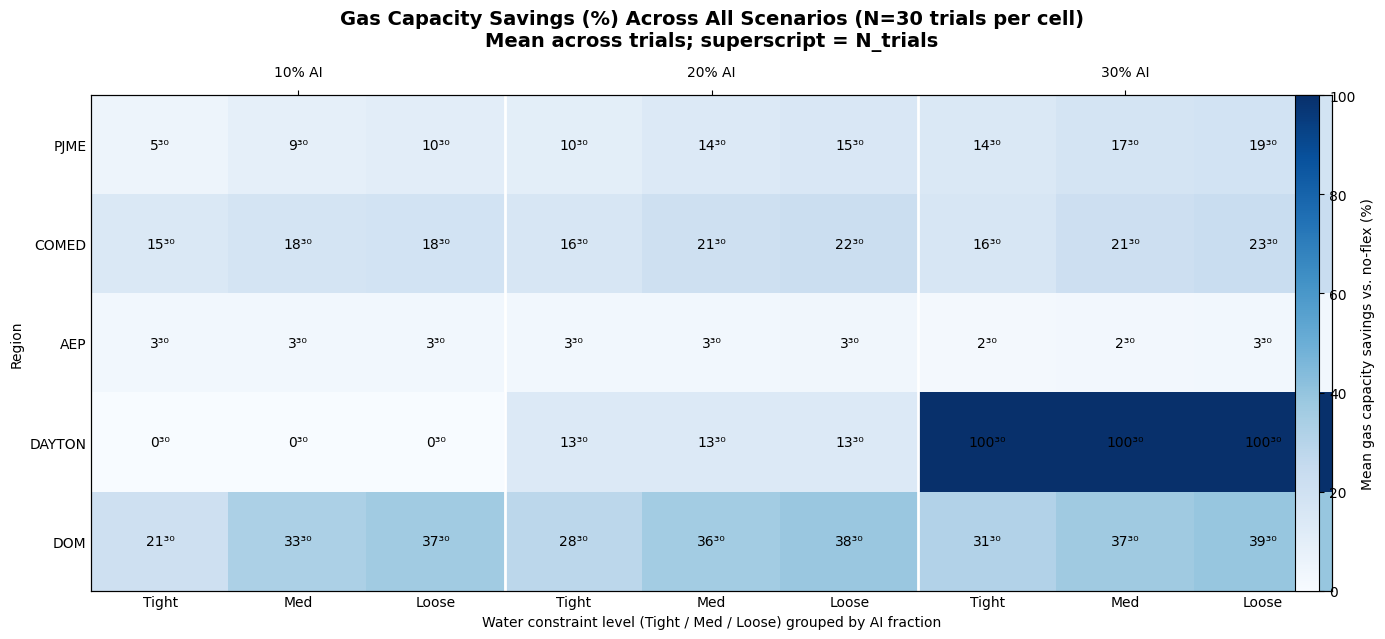

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- helpers ----------
_SUP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
def to_superscript(n: int) -> str:
    """Unicode superscript digits, e.g., 15 -> ¹⁵"""
    return str(int(n)).translate(_SUP)

def add_water_level(out: pd.DataFrame) -> pd.DataFrame:
    """
    Adds a categorical 'water_level' in {Tight, Med, Loose}.
    Uses eps_frac if present; otherwise derives eps_frac from eps_idx within each (region, ai_fraction, trial).
    """
    df = out.copy()
    for c in ["ai_fraction", "eps_idx", "trial", "gas_improve_pct_vs_noflex"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")

    # region string normalize
    if "region" in df.columns:
        df["region"] = df["region"].astype(str).str.strip()

    if "eps_frac" not in df.columns or df["eps_frac"].isna().all():
        # derive eps_frac per trial: eps_idx / max_eps_idx
        if "eps_idx" not in df.columns:
            raise ValueError("Need eps_frac or eps_idx in `out` to define Tight/Med/Loose.")
        g = df.groupby(["region", "ai_fraction", "trial"])["eps_idx"].transform("max")
        df["eps_frac"] = df["eps_idx"] / g.replace(0, np.nan)

    # Cut into thirds
    df["water_level"] = pd.cut(
        df["eps_frac"],
        bins=[-np.inf, 1/3, 2/3, np.inf],
        labels=["Tight", "Med", "Loose"]
    )
    return df


# ---------- main chart ----------
def heatmap_capacity_savings_all_cases(
    out: pd.DataFrame,
    regions_order=None,
    ai_order=None,
    title_extra: str = "",
    figsize=(14, 6.5)
):
    """
    Chart 4: Heatmap of Capacity Savings Across All Cases

    Rows: Regions
    Columns: AI Fraction grouped into 3 subcolumns (Tight/Med/Loose)
    Color: mean gas capacity savings % vs no-flex
    Cell text: mean savings (rounded) + superscript N_trials (unique trials)
    """

    df = add_water_level(out)

    # keep only what we need
    needed = ["region", "ai_fraction", "trial", "water_level", "gas_improve_pct_vs_noflex"]
    missing = [c for c in needed if c not in df.columns]
    if missing:
        raise ValueError(f"`out` missing columns: {missing}")

    df = df.dropna(subset=["region", "ai_fraction", "trial", "water_level", "gas_improve_pct_vs_noflex"]).copy()

    # Order controls
    if regions_order is None:
        regions_order = list(df["region"].unique())
    if ai_order is None:
        ai_order = sorted(df["ai_fraction"].unique())

    # --- aggregate correctly (avoid overweighting ε points) ---
    # 1) per trial average within each water_level band
    per_trial = (
        df.groupby(["region", "ai_fraction", "water_level", "trial"], as_index=False)
          .agg(sav_mean=("gas_improve_pct_vs_noflex", "mean"))
    )

    # 2) across trials: mean savings, and N_trials
    agg = (
        per_trial.groupby(["region", "ai_fraction", "water_level"], as_index=False)
                 .agg(
                     savings_mean=("sav_mean", "mean"),
                     n_trials=("trial", "nunique")
                 )
    )

    # Build full grid of columns: (ai, water_level)
    levels = ["Tight", "Med", "Loose"]
    col_keys = [(a, lv) for a in ai_order for lv in levels]

    # Create matrix for imshow + annotation text
    nR = len(regions_order)
    nC = len(col_keys)

    Z = np.full((nR, nC), np.nan, dtype=float)
    N = np.zeros((nR, nC), dtype=int)

    # Fast lookup
    lookup = {(r, a, lv): (m, n) for r, a, lv, m, n in agg[["region","ai_fraction","water_level","savings_mean","n_trials"]].values}

    for i, r in enumerate(regions_order):
        for j, (a, lv) in enumerate(col_keys):
            key = (str(r), float(a), str(lv))
            if key in lookup:
                m, n = lookup[key]
                Z[i, j] = float(m)
                N[i, j] = int(n)

    # --- plot ---
    fig, ax = plt.subplots(figsize=figsize)

    # Use a blue scale; NaNs show as light gray
    cmap = plt.cm.Blues.copy()
    cmap.set_bad(color="lightgray")

    im = ax.imshow(np.ma.masked_invalid(Z), aspect="auto", cmap=cmap)

    # Row labels (regions)
    ax.set_yticks(np.arange(nR))
    ax.set_yticklabels(regions_order)

    # Bottom x labels: Tight/Med/Loose repeated
    ax.set_xticks(np.arange(nC))
    ax.set_xticklabels([lv for _a in ai_order for lv in levels], rotation=0)

    # Group separators between AI blocks
    for k in range(1, len(ai_order)):
        ax.axvline(k*3 - 0.5, color="white", linewidth=2)

    # Top axis for AI fraction group labels
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    centers = [k*3 + 1 for k in range(len(ai_order))]  # center of each 3-col block
    ax_top.set_xticks(centers)
    ax_top.set_xticklabels([f"{int(round(a*100))}% AI" for a in ai_order])
    ax_top.tick_params(axis="x", pad=8)

    # Cell annotations: "16¹⁵"
    for i in range(nR):
        for j in range(nC):
            if np.isfinite(Z[i, j]):
                txt = f"{Z[i,j]:.0f}{to_superscript(N[i,j])}"
                ax.text(j, i, txt, ha="center", va="center", fontsize=10, color="black")

    # Title + colorbar
    avg_n = int(np.nanmax(N)) if np.nanmax(N) > 0 else 0
    title = "Gas Capacity Savings (%) Across All Scenarios"
    if avg_n:
        title += f" (N={avg_n} trials per cell)"
    if title_extra:
        title += f"\n{title_extra}"
    ax.set_title(title, fontsize=14, fontweight="bold", pad=14)

    cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label("Mean gas capacity savings vs. no-flex (%)")

    # Clean look
    ax.set_xlabel("Water constraint level (Tight / Med / Loose) grouped by AI fraction")
    ax.set_ylabel("Region")
    ax.tick_params(axis="both", length=0)

    plt.tight_layout()
    return fig, ax


# --------- usage ----------
out_path = os.path.join(BASE_DIR, "final_results_epsilon_frontier.csv")
out = pd.read_csv(out_path)

#Optional: enforce a specific region order and AI list (edit as needed)
regions_order = ["PJME","COMED","AEP","DAYTON","DOM"]
ai_order = [0.05, 0.10, 0.20, 0.30]

fig, ax = heatmap_capacity_savings_all_cases(
    out,
    regions_order=None,   # or regions_order
    ai_order=None,        # or ai_order
    title_extra="Mean across trials; superscript = N_trials"
)
plt.show()
